# CSCE 5208 — Backpropagation Lab
## Computation Graphs & Manual Gradient Derivation

**Course:** Neural Networks & Deep Learning  
**Topic:** Backpropagation through a computation graph with `tanh` activation  

---

### Objective
Given the computation graph below, you will:
1. Implement the **forward pass** to compute intermediate values
2. Derive all **gradients** via backpropagation (chain rule)
3. Observe the **vanishing gradient problem** caused by tanh saturation
4. Answer conceptual questions about gradient flow

> **Values in the graph:** weights w0=2, x0=−1, w1=−2, x1=3, w2=1, x2=0.5  
> The network computes: `L = tanh(w0·x0 + w1·x1 + w2·x2)`


---
## Part 1 — Computation Graph

Run the cell below to render the computation graph using `matplotlib`.


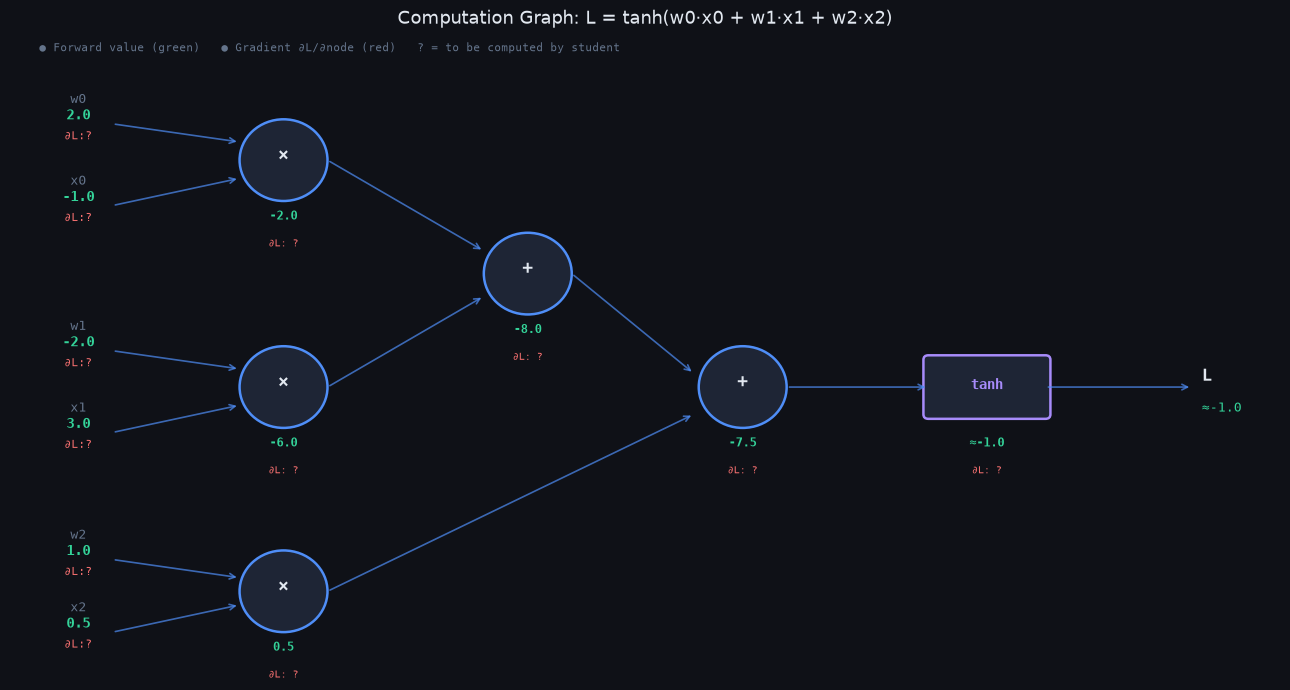

Graph rendered.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 7))
ax.set_xlim(0, 13)
ax.set_ylim(0, 7)
ax.axis('off')
ax.set_facecolor('#0f1117')
fig.patch.set_facecolor('#0f1117')

def node(ax, x, y, label, fwd=None, grad=None, shape='circle', color='#1e2535', edgecolor='#4f8ef7'):
    if shape == 'circle':
        c = plt.Circle((x, y), 0.45, color=color, ec=edgecolor, lw=1.8, zorder=3)
        ax.add_patch(c)
        ax.text(x, y+0.05, label, ha='center', va='center', fontsize=13, color='#e2e8f0',
                fontfamily='monospace', fontweight='bold', zorder=4)
    elif shape == 'rect':
        r = mpatches.FancyBboxPatch((x-0.6, y-0.3), 1.2, 0.6, boxstyle='round,pad=0.05',
                                     fc=color, ec='#a78bfa', lw=1.8, zorder=3)
        ax.add_patch(r)
        ax.text(x, y+0.02, label, ha='center', va='center', fontsize=10, color='#a78bfa',
                fontfamily='monospace', fontweight='bold', zorder=4)
    if fwd is not None:
        ax.text(x, y-0.62, str(fwd), ha='center', va='center', fontsize=8.5,
                color='#34d399', fontfamily='monospace', fontweight='bold', zorder=4)
    if grad is not None:
        ax.text(x, y-0.92, f'∂L: {grad}', ha='center', va='center', fontsize=7.5,
                color='#f87171', fontfamily='monospace', zorder=4)

def leaf(ax, x, y, name, val, grad_str='?'):
    ax.text(x, y+0.18, name, ha='center', fontsize=9, color='#64748b',
            fontfamily='monospace')
    ax.text(x, y,      str(val), ha='center', fontsize=10, color='#34d399',
            fontfamily='monospace', fontweight='bold')
    ax.text(x, y-0.22, f'∂L:{grad_str}', ha='center', fontsize=8, color='#f87171',
            fontfamily='monospace')

def arrow(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color='#4f8ef7', lw=1.2, alpha=0.7))

# Leaf inputs
leaf(ax, 0.7, 6.1, 'w0', '2.0')
leaf(ax, 0.7, 5.2, 'x0', '-1.0')
leaf(ax, 0.7, 3.6, 'w1', '-2.0')
leaf(ax, 0.7, 2.7, 'x1', '3.0')
leaf(ax, 0.7, 1.3, 'w2', '1.0')
leaf(ax, 0.7, 0.5, 'x2', '0.5')

# Multiply nodes
node(ax, 2.8, 5.65, '×', fwd='-2.0', grad='?')
node(ax, 2.8, 3.15, '×', fwd='-6.0', grad='?')
node(ax, 2.8, 0.9,  '×', fwd='0.5',  grad='?')

# Add nodes
node(ax, 5.3, 4.4,  '+', fwd='-8.0', grad='?')
node(ax, 7.5, 3.15, '+', fwd='-7.5', grad='?')

# tanh node
node(ax, 10.0, 3.15, 'tanh', fwd='≈-1.0', grad='?', shape='rect')

# Output
ax.text(12.2, 3.22, 'L', fontsize=12, color='#e2e8f0', fontfamily='monospace', fontweight='bold')
ax.text(12.2, 2.88, '≈-1.0', fontsize=9, color='#34d399', fontfamily='monospace')

# Arrows: leaves → multiply
arrow(ax, 1.05, 6.05, 2.35, 5.85)
arrow(ax, 1.05, 5.15, 2.35, 5.45)
arrow(ax, 1.05, 3.55, 2.35, 3.35)
arrow(ax, 1.05, 2.65, 2.35, 2.95)
arrow(ax, 1.05, 1.25, 2.35, 1.05)
arrow(ax, 1.05, 0.45, 2.35, 0.75)

# Multiply → add1
arrow(ax, 3.25, 5.65, 4.85, 4.65)
arrow(ax, 3.25, 3.15, 4.85, 4.15)

# Multiply(s2) → add2
arrow(ax, 3.25, 0.9, 7.0, 2.85)

# Add1 → add2
arrow(ax, 5.75, 4.4, 7.0, 3.3)

# Add2 → tanh
arrow(ax, 7.95, 3.15, 9.4, 3.15)

# tanh → output
arrow(ax, 10.6, 3.15, 12.1, 3.15)

# Legend
ax.text(0.3, 6.85, '● Forward value (green)   ● Gradient ∂L/∂node (red)   ? = to be computed by student',
        fontsize=8, color='#64748b', fontfamily='monospace')
ax.set_title('Computation Graph: L = tanh(w0·x0 + w1·x1 + w2·x2)',
             color='#e2e8f0', fontsize=13, pad=10)

plt.tight_layout()
plt.savefig('computation_graph.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
print("Graph rendered.")


---
## Part 2 — Forward Pass

**Task:** Fill in the `???` placeholders below. Compute each intermediate value step by step.

> **Inputs:** w0=2, x0=−1, w1=−2, x1=3, w2=1, x2=0.5


In [2]:
import numpy as np

# ── Given inputs ─────────────────────────────────────────────────────────────yes

w0, x0 =  2.0, -1.0
w1, x1 = -2.0,  3.0
w2, x2 =  1.0,  0.5

# ── TODO: Fill in each intermediate value ─────────────────────────────────────
s0 = -2.0         # w0 * x0
s1 = -6.0         # w1 * x1
s2 = 0.5         # w2 * x2
s3 = -8.0          # s0 + s1     (first add gate)
s4 = -7.5         # s3 + s2     (second add gate — this is the pre-activation)
L  = np.tanh(s4)         # tanh(s4)    (output)

print(f"s0 = w0 * x0  = {w0} * {x0}  = {s0}")
print(f"s1 = w1 * x1  = {w1} * {x1}  = {s1}")
print(f"s2 = w2 * x2  = {w2} * {x2}  = {s2}")
print(f"s3 = s0 + s1  = {s0} + {s1}  = {s3}")
print(f"s4 = s3 + s2  = {s3} + {s2}  = {s4}")
print(f"L  = tanh(s4) = tanh({s4})  = {L:.6f}")


s0 = w0 * x0  = 2.0 * -1.0  = -2.0
s1 = w1 * x1  = -2.0 * 3.0  = -6.0
s2 = w2 * x2  = 1.0 * 0.5  = 0.5
s3 = s0 + s1  = -2.0 + -6.0  = -8.0
s4 = s3 + s2  = -8.0 + 0.5  = -7.5
L  = tanh(s4) = tanh(-7.5)  = -0.999999


### ✏️ Reflection — Forward Pass

Answer in the cell below:

1. What is the value of `s4` (the pre-activation input to tanh)?
2. `tanh(-7.5)` is very close to `−1`. What does it mean when a tanh neuron outputs ±1?
3. Is this neuron in a **saturated** or **unsaturated** region? How can you tell?


*Your answers here:*

1. The value of s4 is -7.5 (s0 + s1 + s2 + s3)
2. Tanh makes any real number in the range of (-1, 1). As its input gets very negative, the output approaches -1, but never equals to -1, also same near the +1. So the output (+-) 1 means the neuron has hit the flat, asymptotic tail of the curve, and the output barely changes a lot in that direction beyond those values. 
3. In a saturated region the tanh curve is flat and the derivative slope is nearly zero. The output of -0.99998 is very clode to the boundary which makes it a saturated region.


---
## Part 3 — Backward Pass (Backpropagation)

### Derivative Reference

| Gate | Forward | Local gradient |
|------|---------|---------------|
| Multiply: `z = a × b` | `z` | `∂z/∂a = b`, `∂z/∂b = a` |
| Add: `z = a + b` | `z` | `∂z/∂a = 1`, `∂z/∂b = 1` |
| tanh: `z = tanh(a)` | `z` | `∂z/∂a = 1 − z²` |

**Chain rule:** `grad_a = grad_z × (∂z/∂a)`

---
**Task:** Fill in all `???` values below.


In [3]:
# ── Backward Pass ─────────────────────────────────────────────────────────────
# Assume L has been computed from the forward pass above.
# We differentiate L with respect to itself first.

grad_L  = 1.0                        # ∂L/∂L = 1 always

# tanh gate: d/dx tanh(x) = 1 - tanh²(x)
grad_s4 = grad_L * (1 - L**2)         # grad_L * (1 - L**2)

# Second add gate (s4 = s3 + s2): passes gradient to both inputs unchanged
grad_s3 = grad_s4 * 1                 # grad_s4 * 1
grad_s2 = grad_s4 * 1                 # grad_s4 * 1

# First add gate (s3 = s0 + s1): passes gradient to both inputs unchanged
grad_s0 = grad_s3 * 1                 # grad_s3 * 1
grad_s1 = grad_s3 * 1                 # grad_s3 * 1

# Multiply gate for s0 = w0 * x0
grad_w0 = grad_s0 * x0                # grad_s0 * x0
grad_x0 = grad_s0 * w0                # grad_s0 * w0

# Multiply gate for s1 = w1 * x1
grad_w1 = grad_s1 * x1                # grad_s1 * x1
grad_x1 = grad_s1 * w1                # grad_s1 * w1

# Multiply gate for s2 = w2 * x2
grad_w2 = grad_s2 * x2                # grad_s2 * x2
grad_x2 = grad_s2 * w2                # grad_s2 * w2

print("── Backward Pass Results ─────────────────────────────")
print(f"grad_L  = {grad_L}")
print(f"grad_s4 = grad_L  × (1 - L²) = 1.0 × (1 - ({L:.4f})²) = {grad_s4:.6f}")
print(f"grad_s3 = grad_s4 = {grad_s3:.6f}")
print(f"grad_s2 = grad_s4 = {grad_s2:.6f}")
print(f"grad_s0 = grad_s3 = {grad_s0:.6f}")
print(f"grad_s1 = grad_s3 = {grad_s1:.6f}")
print(f"grad_w0 = grad_s0 × x0 = {grad_s0:.6f} × {x0} = {grad_w0:.6f}")
print(f"grad_x0 = grad_s0 × w0 = {grad_s0:.6f} × {w0} = {grad_x0:.6f}")
print(f"grad_w1 = grad_s1 × x1 = {grad_s1:.6f} × {x1} = {grad_w1:.6f}")
print(f"grad_x1 = grad_s1 × w1 = {grad_s1:.6f} × {w1} = {grad_x1:.6f}")
print(f"grad_w2 = grad_s2 × x2 = {grad_s2:.6f} × {x2} = {grad_w2:.6f}")
print(f"grad_x2 = grad_s2 × w2 = {grad_s2:.6f} × {w2} = {grad_x2:.6f}")


── Backward Pass Results ─────────────────────────────
grad_L  = 1.0
grad_s4 = grad_L  × (1 - L²) = 1.0 × (1 - (-1.0000)²) = 0.000001
grad_s3 = grad_s4 = 0.000001
grad_s2 = grad_s4 = 0.000001
grad_s0 = grad_s3 = 0.000001
grad_s1 = grad_s3 = 0.000001
grad_w0 = grad_s0 × x0 = 0.000001 × -1.0 = -0.000001
grad_x0 = grad_s0 × w0 = 0.000001 × 2.0 = 0.000002
grad_w1 = grad_s1 × x1 = 0.000001 × 3.0 = 0.000004
grad_x1 = grad_s1 × w1 = 0.000001 × -2.0 = -0.000002
grad_w2 = grad_s2 × x2 = 0.000001 × 0.5 = 0.000001
grad_x2 = grad_s2 × w2 = 0.000001 × 1.0 = 0.000001


### ✏️ Reflection — Backward Pass

Answer in the cell below:

1. What is `grad_s4`? Why is it so small?
2. What happens to `grad_w0`, `grad_w1`, `grad_w2` as a result?
3. If you ran one step of gradient descent (`w ← w − lr × grad_w`), would the weights change meaningfully? Why or why not?


*Your answers here:*

1. grad_s4 nearly equals to 0.000001. It is small because L value of -0.9999997 is deep in tanh's saturated region, where the curve is nearly flat (slope approaches to 0).
2. grad_w0, grad_w1, grad_w2 all become similarly small, since they are each computed by scaling this near-zero gradient.
3. No — with grad_w ~1e-6, even a normal learning rate produces a weight change of ~1e-7 to 1e-8, which is negligible. Training effectively stalls.


---
## Part 4 — Numerical Verification with PyTorch

Use PyTorch's autograd to verify your manually computed gradients.


In [4]:
import torch

# Define inputs as tensors with gradient tracking
w0t = torch.tensor(2.0,  requires_grad=True)
x0t = torch.tensor(-1.0, requires_grad=True)
w1t = torch.tensor(-2.0, requires_grad=True)
x1t = torch.tensor(3.0,  requires_grad=True)
w2t = torch.tensor(1.0,  requires_grad=True)
x2t = torch.tensor(0.5,  requires_grad=True)

# Forward pass
s0t = w0t * x0t
s1t = w1t * x1t
s2t = w2t * x2t
s3t = s0t + s1t
s4t = s3t + s2t
Lt  = torch.tanh(s4t)

# Backward pass (autograd computes all gradients)
Lt.backward()

print("── PyTorch Autograd Gradients ────────────────────────")
print(f"L        = {Lt.item():.6f}")
print(f"grad_w0  = {w0t.grad.item():.6f}")
print(f"grad_x0  = {x0t.grad.item():.6f}")
print(f"grad_w1  = {w1t.grad.item():.6f}")
print(f"grad_x1  = {x1t.grad.item():.6f}")
print(f"grad_w2  = {w2t.grad.item():.6f}")
print(f"grad_x2  = {x2t.grad.item():.6f}")
print()
print("── Comparison: Manual vs PyTorch ─────────────────────")
tol = 1e-5
pairs = [('grad_w0', grad_w0, w0t.grad.item()),
         ('grad_x0', grad_x0, x0t.grad.item()),
         ('grad_w1', grad_w1, w1t.grad.item()),
         ('grad_x1', grad_x1, x1t.grad.item()),
         ('grad_w2', grad_w2, w2t.grad.item()),
         ('grad_x2', grad_x2, x2t.grad.item())]
all_match = True
for name, manual, auto in pairs:
    match = abs(manual - auto) < tol
    status = '✓ MATCH' if match else '✗ MISMATCH'
    if not match: all_match = False
    print(f"  {name:10s}: manual={manual:.6f}  pytorch={auto:.6f}  {status}")
print()
print("All gradients match!" if all_match else "Some gradients differ — check your work above.")


── PyTorch Autograd Gradients ────────────────────────
L        = -0.999999
grad_w0  = -0.000001
grad_x0  = 0.000002
grad_w1  = 0.000004
grad_x1  = -0.000002
grad_w2  = 0.000001
grad_x2  = 0.000001

── Comparison: Manual vs PyTorch ─────────────────────
  grad_w0   : manual=-0.000001  pytorch=-0.000001  ✓ MATCH
  grad_x0   : manual=0.000002  pytorch=0.000002  ✓ MATCH
  grad_w1   : manual=0.000004  pytorch=0.000004  ✓ MATCH
  grad_x1   : manual=-0.000002  pytorch=-0.000002  ✓ MATCH
  grad_w2   : manual=0.000001  pytorch=0.000001  ✓ MATCH
  grad_x2   : manual=0.000001  pytorch=0.000001  ✓ MATCH

All gradients match!


---
## Part 5 — The Vanishing Gradient Problem

Explore how the magnitude of `grad_s4 = (1 − tanh²(s4))` changes across different pre-activation values.


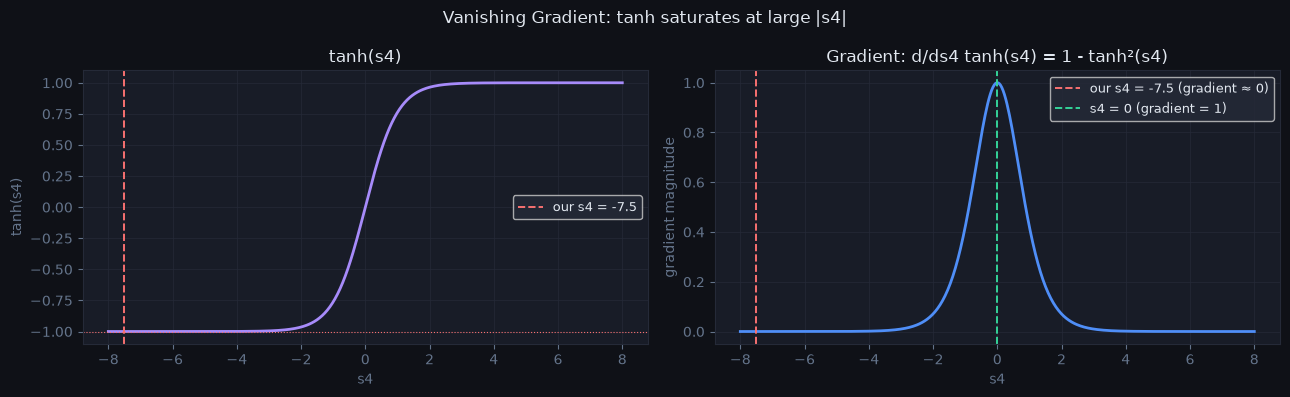

s4 =  -7.5  →  grad_s4 = 0.000001
s4 =  -2.0  →  grad_s4 = 0.070651
s4 =  -0.5  →  grad_s4 = 0.786448
s4 =   0.0  →  grad_s4 = 1.000000
s4 =   0.5  →  grad_s4 = 0.786448
s4 =   2.0  →  grad_s4 = 0.070651
s4 =   7.5  →  grad_s4 = 0.000001


In [5]:
import numpy as np
import matplotlib.pyplot as plt

s4_range = np.linspace(-8, 8, 400)
tanh_vals = np.tanh(s4_range)
grad_tanh  = 1 - tanh_vals**2         # d/dx tanh(x)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.patch.set_facecolor('#0f1117')
for ax in axes:
    ax.set_facecolor('#181c27')
    ax.tick_params(colors='#64748b')
    for spine in ax.spines.values():
        spine.set_edgecolor('#252a38')

# Left: tanh curve
axes[0].plot(s4_range, tanh_vals, color='#a78bfa', lw=2)
axes[0].axvline(-7.5, color='#f87171', lw=1.4, linestyle='--', label='our s4 = -7.5')
axes[0].axhline(-1.0, color='#f87171', lw=0.8, linestyle=':')
axes[0].set_title('tanh(s4)', color='#e2e8f0')
axes[0].set_xlabel('s4', color='#64748b')
axes[0].set_ylabel('tanh(s4)', color='#64748b')
axes[0].legend(facecolor='#252a38', labelcolor='#e2e8f0', fontsize=9)
axes[0].grid(True, color='#252a38', lw=0.5)

# Right: gradient curve
axes[1].plot(s4_range, grad_tanh, color='#4f8ef7', lw=2)
axes[1].axvline(-7.5, color='#f87171', lw=1.4, linestyle='--', label='our s4 = -7.5 (gradient ≈ 0)')
axes[1].axvline(0,    color='#34d399', lw=1.4, linestyle='--', label='s4 = 0 (gradient = 1)')
axes[1].set_title('Gradient: d/ds4 tanh(s4) = 1 - tanh²(s4)', color='#e2e8f0')
axes[1].set_xlabel('s4', color='#64748b')
axes[1].set_ylabel('gradient magnitude', color='#64748b')
axes[1].legend(facecolor='#252a38', labelcolor='#e2e8f0', fontsize=9)
axes[1].grid(True, color='#252a38', lw=0.5)

plt.suptitle('Vanishing Gradient: tanh saturates at large |s4|', color='#e2e8f0', fontsize=12)
plt.tight_layout()
plt.savefig('vanishing_gradient.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

# Print values at key points
for s in [-7.5, -2.0, -0.5, 0.0, 0.5, 2.0, 7.5]:
    g = 1 - np.tanh(s)**2
    print(f"s4 = {s:5.1f}  →  grad_s4 = {g:.6f}")


### ✏️ Reflection — Vanishing Gradients

1. At `s4 = -7.5`, the gradient is essentially 0. What does this mean for weight updates during training?
2. At `s4 = 0`, the gradient equals 1.0. Why is this the ideal operating point for tanh?
3. **ReLU alternative:** ReLU(x) = max(0, x), with derivative = 1 for x > 0, 0 for x ≤ 0. If we replaced tanh with ReLU and s4 = -7.5, what would `grad_s4` be? Is this better or worse?
4. Name one advantage and one disadvantage of ReLU over tanh.


*Your answers here:*

1. Essentially no update happens — the weight is effectively "stuck" and training stalls for that neuron.
2. At s4=0, the gradient is at its maximum (1.0), so the full gradient signal passes through unattenuated — this is the fastest, most reliable learning regime.
3. grad_s4 would be 0 (since -7.5 ≤ 0). Same outcome as tanh here (both ≈0) — no improvement in this specific saturated case.
4. Advantage: ReLU doesn't saturate for positive inputs, so gradients don't vanish there, enabling faster training in deep nets. Disadvantage: "dying ReLU" — neurons with negative input get exactly 0 gradient and can stop learning permanently, unlike tanh which is at least smooth (just very small).


---
## Part 6 — Bonus: Unsaturated Regime

**What if the weights produced `s4 = 0` instead?**  
Recompute the full backward pass for this case and compare.


In [6]:
# Bonus: use modified weights so that s4 = 0
# e.g., w0=1, x0=0, w1=1, x1=0, w2=0, x2=0  → s4 = 0
# Or find your own weights that give s4 = 0.

# TODO: Choose weights such that s4 = 0, then run the full forward + backward pass.

w0_b, x0_b = 1.0, 0.0
w1_b, x1_b = 1.0, 0.0
w2_b, x2_b = 0.0, 0.0

s0_b = w0_b * x0_b
s1_b = w1_b * x1_b
s2_b = w2_b * x2_b
s3_b = s0_b + s1_b
s4_b = s3_b + s2_b
L_b  = np.tanh(s4_b)

print(f"s4  = {s4_b}   (should be 0)")
print(f"L   = {L_b:.4f}   (should be 0)")

grad_L_b  = 1.0
grad_s4_b = grad_L_b * (1 - L_b**2)
print(f"\ngrad_s4 = 1 * (1 - {L_b:.4f}²) = {grad_s4_b:.4f}   ← compare to {1 - np.tanh(-7.5)**2:.6f} from Part 3!")
print()
print("All downstream gradients will scale by", grad_s4_b, "instead of ≈ 0")
print("→ Weights WILL update meaningfully — no vanishing gradient here.")


s4  = 0.0   (should be 0)
L   = 0.0000   (should be 0)

grad_s4 = 1 * (1 - 0.0000²) = 1.0000   ← compare to 0.000001 from Part 3!

All downstream gradients will scale by 1.0 instead of ≈ 0
→ Weights WILL update meaningfully — no vanishing gradient here.


---
## Summary

| Concept | Key Takeaway |
|---------|-------------|
| **Forward pass** | Compute node values left→right using inputs and operations |
| **Backward pass** | Apply chain rule right→left; multiply upstream gradient by local gradient |
| **Add gate** | Gradient distributor — passes upstream grad unchanged to both inputs |
| **Multiply gate** | Gradient switcher — each input's grad = upstream_grad × *the other* input |
| **tanh derivative** | `1 − tanh²(x)` — approaches 0 at saturation (|x| ≫ 0) |
| **Vanishing gradient** | When activation saturates, gradients → 0, and weights stop updating |
| **Mitigation** | Use ReLU/Leaky ReLU, proper weight init, batch norm, or residual connections |

---
*CSCE 5208 — Neural Networks & Deep Learning*  
*Backpropagation Lab — Computation Graphs*
